In [1]:
import numpy as np
import pandas as pd
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load the dataset

file_path = "../dataset/FairCVdb.npy"

faircv = np.load(file_path, allow_pickle=True)

# Convert into dictionary if required
if isinstance(faircv, np.ndarray):
    faircv = faircv.item()

print("Dataset loaded successfully!")
print("Dataset type:", type(faircv))

Dataset loaded successfully!
Dataset type: <class 'dict'>


In [3]:
print("Dataset contains the following keys:\n")

for key in faircv.keys():
    print(key)

Dataset contains the following keys:

Profiles Train
Profiles Test
Bios Train
Bios Test
Names Train
Names Test
Blind Labels Train
Blind Labels Test
Biased Labels Train (Gender)
Biased Labels Test (Gender)
Biased Labels Train (Ethnicity)
Biased Labels Test (Ethnicity)
Image List Train
Image List Test


In [4]:
# Check the shape of the training and testing profiles

print("Training Profiles Shape:", faircv["Profiles Train"].shape)
print("Testing Profiles Shape:", faircv["Profiles Test"].shape)

print("\nTraining Labels Shape:")
print("Blind:", faircv["Blind Labels Train"].shape)
print("Gender:", faircv["Biased Labels Train (Gender)"].shape)
print("Ethnicity:", faircv["Biased Labels Train (Ethnicity)"].shape)

print("\nTesting Labels Shape:")
print("Blind:", faircv["Blind Labels Test"].shape)
print("Gender:", faircv["Biased Labels Test (Gender)"].shape)
print("Ethnicity:", faircv["Biased Labels Test (Ethnicity)"].shape)

Training Profiles Shape: (19200, 51)
Testing Profiles Shape: (4800, 51)

Training Labels Shape:
Blind: (19200,)
Gender: (19200,)
Ethnicity: (19200,)

Testing Labels Shape:
Blind: (4800,)
Gender: (4800,)
Ethnicity: (4800,)


In [5]:
# Check unique values and their frequencies

labels = [
    "Blind Labels Train",
    "Biased Labels Train (Gender)",
    "Biased Labels Train (Ethnicity)"
]

for label in labels:
    print("\n", label)
    print(pd.Series(faircv[label].flatten()).value_counts().sort_index())


 Blind Labels Train
0.000000    1
0.024291    1
0.033470    1
0.034950    1
0.043760    1
           ..
0.878877    1
0.891148    1
0.898216    1
0.899551    1
0.923230    1
Name: count, Length: 19200, dtype: int64

 Biased Labels Train (Gender)
0.000000    20
0.000806     1
0.004914     1
0.005211     1
0.006097     1
            ..
0.870113     1
0.870876     1
0.878877     1
0.898216     1
0.899551     1
Name: count, Length: 19181, dtype: int64

 Biased Labels Train (Ethnicity)
0.000000    15
0.000756     1
0.001667     1
0.002389     1
0.004604     1
            ..
0.948441     1
0.959650     1
0.975557     1
0.976815     1
1.000000     1
Name: count, Length: 19186, dtype: int64


In [6]:
# Check statistics of all three training labels

labels = [
    "Blind Labels Train",
    "Biased Labels Train (Gender)",
    "Biased Labels Train (Ethnicity)"
]

for label in labels:

    print("\n", label)

    data = faircv[label]

    print("Data Type:", data.dtype)
    print("Minimum:", np.min(data))
    print("Maximum:", np.max(data))
    print("Mean:", np.mean(data))
    print("Unique Values:", len(np.unique(data)))


 Blind Labels Train
Data Type: float64
Minimum: 0.0
Maximum: 0.9232296308037875
Mean: 0.41854257104626963
Unique Values: 19200

 Biased Labels Train (Gender)
Data Type: float64
Minimum: 0.0
Maximum: 0.8995512191299637
Mean: 0.3713001061430182
Unique Values: 19181

 Biased Labels Train (Ethnicity)
Data Type: float64
Minimum: 0.0
Maximum: 1.0
Mean: 0.41855282558696427
Unique Values: 19186


In [7]:
# Inspect profile features

profiles = faircv["Profiles Train"]

print("Data Type:", profiles.dtype)

print("\nFirst 5 Profiles:")
print(profiles[:5])

print("\nMissing Values:", np.isnan(profiles).sum())

print("\nFeature Minimum:", np.min(profiles))
print("Feature Maximum:", np.max(profiles))

Data Type: float64

First 5 Profiles:
[[ 1.00000000e+00  0.00000000e+00  4.00000000e+00  2.50000000e-01
   6.00000000e-01  8.00000000e-01  0.00000000e+00  1.00000000e+00
   6.00000000e-01  1.00000000e+00  4.00000000e-01  2.74226516e-01
   4.47412729e-02 -3.43037784e-01  1.98491961e-01  1.84808105e-01
  -1.78579047e-01  2.95215696e-01  1.33798912e-01  4.32679743e-01
  -9.77739990e-02  2.51825720e-01 -9.31767002e-02  2.78677255e-01
  -7.27646351e-02 -8.26743394e-02 -5.02222292e-02  3.16111714e-01
   9.12411585e-02 -1.41069412e-01  3.24484676e-01 -2.82459706e-01
   2.02021837e-01  2.63071924e-01  1.96385533e-01  1.54401898e-01
   3.04056227e-01 -1.89887360e-01  2.20521241e-01  1.83633804e-01
  -2.29503512e-01  2.15913549e-01 -1.11406364e-01  1.41465589e-01
  -4.46474493e-01  2.05603838e-01 -1.64415583e-01 -1.43908009e-01
   1.30595416e-01 -1.70221478e-01 -2.64257461e-01]
 [ 2.00000000e+00  0.00000000e+00  6.00000000e+00  1.00000000e+00
   4.00000000e-01  4.00000000e-01  0.00000000e+00  8.

In [8]:
# Check demographic attributes

profiles = faircv["Profiles Train"]

print("Ethnicity Distribution:")
print(pd.Series(profiles[:, 0]).value_counts().sort_index())

print("\nGender Distribution:")
print(pd.Series(profiles[:, 1]).value_counts().sort_index())

Ethnicity Distribution:
0.0    6405
1.0    6412
2.0    6383
Name: count, dtype: int64

Gender Distribution:
0.0    9563
1.0    9637
Name: count, dtype: int64


In [9]:
# Define the structured feature names

feature_names = [
    "Occupation",
    "Suitability",
    "Education",
    "Experience",
    "Recommendation",
    "Availability",
    "Language_1",
    "Language_2",
    "Language_3"
]

# Extract columns 2 to 10
X_train = faircv["Profiles Train"][:, 2:11]
X_test = faircv["Profiles Test"][:, 2:11]

# Convert into DataFrames
X_train = pd.DataFrame(X_train, columns=feature_names)
X_test = pd.DataFrame(X_test, columns=feature_names)

print("Training Features:")
print(X_train.head())

print("\nTesting Features Shape:", X_test.shape)

Training Features:
   Occupation  Suitability  Education  Experience  Recommendation  \
0         4.0         0.25        0.6         0.8             0.0   
1         6.0         1.00        0.4         0.4             0.0   
2         5.0         0.25        0.2         0.8             0.0   
3         0.0         0.75        0.2         0.4             0.0   
4         8.0         0.50        0.2         0.4             1.0   

   Availability  Language_1  Language_2  Language_3  
0           1.0         0.6         1.0         0.4  
1           0.8         0.8         0.6         0.4  
2           0.8         0.0         1.0         0.2  
3           0.8         0.0         0.0         1.0  
4           1.0         0.0         1.0         0.4  

Testing Features Shape: (4800, 9)


In [10]:
# Prepare target variables

y_train = {
    "Blind": faircv["Blind Labels Train"],
    "Gender": faircv["Biased Labels Train (Gender)"],
    "Ethnicity": faircv["Biased Labels Train (Ethnicity)"]
}

y_test = {
    "Blind": faircv["Blind Labels Test"],
    "Gender": faircv["Biased Labels Test (Gender)"],
    "Ethnicity": faircv["Biased Labels Test (Ethnicity)"]
}

# Display target information

for name in y_train:

    print("\n", name, "Target")

    print("Training shape:", y_train[name].shape)
    print("Testing shape:", y_test[name].shape)
    print("Training mean:", np.mean(y_train[name]))
    print("Testing mean:", np.mean(y_test[name]))

print("\nTarget variables prepared successfully!")


 Blind Target
Training shape: (19200,)
Testing shape: (4800,)
Training mean: 0.41854257104626963
Testing mean: 0.4152976426465466

 Gender Target
Training shape: (19200,)
Testing shape: (4800,)
Training mean: 0.3713001061430182
Testing mean: 0.3687953974632267

 Ethnicity Target
Training shape: (19200,)
Testing shape: (4800,)
Training mean: 0.41855282558696427
Testing mean: 0.41496767908030446

Target variables prepared successfully!


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [12]:
# Create Linear Regression model

lr_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Train the model using Blind labels

lr_model.fit(X_train, y_train["Blind"])

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [13]:
# Predict Blind scores

lr_predictions = lr_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test["Blind"][:10])

print("\nFirst 10 Predicted Values:")
print(lr_predictions[:10])

First 10 Actual Values:
[0.42797914 0.29575293 0.38243269 0.26638514 0.3688526  0.54109282
 0.34820519 0.41950563 0.41895031 0.28966168]

First 10 Predicted Values:
[0.43495744 0.30558053 0.37624342 0.28195406 0.36443391 0.53518149
 0.34702691 0.42333737 0.39949243 0.30570802]


In [14]:
# Calculate performance metrics

mae = mean_absolute_error(y_test["Blind"], lr_predictions)

mse = mean_squared_error(y_test["Blind"], lr_predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test["Blind"], lr_predictions)

print("Linear Regression - Blind Target")
print("--------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression - Blind Target
--------------------------------
MAE: 0.009399300976255447
MSE: 0.0001386222394302203
RMSE: 0.011773794606252493
R2 Score: 0.9911557623812715


In [15]:
gender_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

gender_model.fit(X_train, y_train["Gender"])

print("Linear Regression model for Gender target trained successfully!")

Linear Regression model for Gender target trained successfully!


In [16]:
gender_predictions = gender_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test["Gender"][:10])

print("\nFirst 10 Predicted Values:")
print(gender_predictions[:10])

First 10 Actual Values:
[0.42797914 0.29575293 0.38243269 0.26638514 0.3688526  0.43287692
 0.22804332 0.41950563 0.34036968 0.18280311]

First 10 Predicted Values:
[0.38928516 0.25853545 0.32957523 0.23406765 0.31693188 0.48855293
 0.30309657 0.37754823 0.35245024 0.25928263]


In [17]:
gender_mae = mean_absolute_error(y_test["Gender"], gender_predictions)
gender_mse = mean_squared_error(y_test["Gender"], gender_predictions)
gender_rmse = np.sqrt(gender_mse)
gender_r2 = r2_score(y_test["Gender"], gender_predictions)

print("Linear Regression - Gender Target")
print("---------------------------------")
print("MAE:", gender_mae)
print("MSE:", gender_mse)
print("RMSE:", gender_rmse)
print("R2 Score:", gender_r2)

Linear Regression - Gender Target
---------------------------------
MAE: 0.04735231933345516
MSE: 0.002530629915509747
RMSE: 0.05030536666708381
R2 Score: 0.8599852311254292


In [18]:
ethnicity_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

ethnicity_model.fit(X_train, y_train["Ethnicity"])

print("Linear Regression model for Ethnicity target trained successfully!")

Linear Regression model for Ethnicity target trained successfully!


In [19]:
ethnicity_predictions = ethnicity_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test["Ethnicity"][:10])

print("\nFirst 10 Predicted Values:")
print(ethnicity_predictions[:10])

First 10 Actual Values:
[0.42797914 0.40699021 0.49091462 0.35053291 0.29401186 0.45783384
 0.44415294 0.41950563 0.41895031 0.37817996]

First 10 Predicted Values:
[0.46089029 0.30308287 0.40122137 0.29373403 0.32840401 0.51314781
 0.3568504  0.45758978 0.41424362 0.32709198]


In [20]:
ethnicity_mae = mean_absolute_error(y_test["Ethnicity"], ethnicity_predictions)
ethnicity_mse = mean_squared_error(y_test["Ethnicity"], ethnicity_predictions)
ethnicity_rmse = np.sqrt(ethnicity_mse)
ethnicity_r2 = r2_score(y_test["Ethnicity"], ethnicity_predictions)

print("Linear Regression - Ethnicity Target")
print("------------------------------------")
print("MAE:", ethnicity_mae)
print("MSE:", ethnicity_mse)
print("RMSE:", ethnicity_rmse)
print("R2 Score:", ethnicity_r2)

Linear Regression - Ethnicity Target
------------------------------------
MAE: 0.0617050980945294
MSE: 0.005256029720308706
RMSE: 0.07249848081379848
R2 Score: 0.7603964139096749


In [21]:
linear_results = pd.DataFrame({
    "Target": ["Blind", "Gender", "Ethnicity"],
    "MAE": [mae, gender_mae, ethnicity_mae],
    "MSE": [mse, gender_mse, ethnicity_mse],
    "RMSE": [rmse, gender_rmse, ethnicity_rmse],
    "R2 Score": [r2, gender_r2, ethnicity_r2]
})

linear_results

,Target,MAE,MSE,RMSE,R2 Score
0,Blind,0.009399,0.000139,0.011774,0.991156
1,Gender,0.047352,0.002531,0.050305,0.859985
2,Ethnicity,0.061705,0.005256,0.072498,0.760396


In [22]:
linear_results.to_csv(
    "../results/linear_regression_results.csv",
    index=False
)

print("Linear Regression results saved successfully!")

Linear Regression results saved successfully!


In [23]:
from sklearn.ensemble import RandomForestRegressor

In [24]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train["Blind"])

print("Random Forest model for Blind target trained successfully!")

Random Forest model for Blind target trained successfully!


In [25]:
rf_predictions = rf_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test["Blind"][:10])

print("\nFirst 10 Predicted Values:")
print(rf_predictions[:10])

First 10 Actual Values:
[0.42797914 0.29575293 0.38243269 0.26638514 0.3688526  0.54109282
 0.34820519 0.41950563 0.41895031 0.28966168]

First 10 Predicted Values:
[0.42761251 0.29185145 0.38720514 0.29766271 0.3611211  0.5438137
 0.3316591  0.41101223 0.39024633 0.30408321]


In [26]:
rf_mae = mean_absolute_error(y_test["Blind"], rf_predictions)
rf_mse = mean_squared_error(y_test["Blind"], rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test["Blind"], rf_predictions)

print("Random Forest - Blind Target")
print("-----------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest - Blind Target
-----------------------------
MAE: 0.016885321999805095
MSE: 0.0004920619568386444
RMSE: 0.022182469583854822
R2 Score: 0.968605954662793


In [27]:
rf_gender_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_gender_model.fit(X_train, y_train["Gender"])

print("Random Forest model for Gender target trained successfully!")

Random Forest model for Gender target trained successfully!


In [28]:
rf_gender_predictions = rf_gender_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test["Gender"][:10])

print("\nFirst 10 Predicted Values:")
print(rf_gender_predictions[:10])

First 10 Actual Values:
[0.42797914 0.29575293 0.38243269 0.26638514 0.3688526  0.43287692
 0.22804332 0.41950563 0.34036968 0.18280311]

First 10 Predicted Values:
[0.38825044 0.2482519  0.28273869 0.24294095 0.28614784 0.46690534
 0.30841249 0.40325548 0.36529434 0.29921682]


In [29]:
rf_gender_mae = mean_absolute_error(y_test["Gender"], rf_gender_predictions)
rf_gender_mse = mean_squared_error(y_test["Gender"], rf_gender_predictions)
rf_gender_rmse = np.sqrt(rf_gender_mse)
rf_gender_r2 = r2_score(y_test["Gender"], rf_gender_predictions)

print("Random Forest - Gender Target")
print("------------------------------")
print("MAE:", rf_gender_mae)
print("MSE:", rf_gender_mse)
print("RMSE:", rf_gender_rmse)
print("R2 Score:", rf_gender_r2)

Random Forest - Gender Target
------------------------------
MAE: 0.04969931483761628
MSE: 0.0033393478487998363
RMSE: 0.057787090676031064
R2 Score: 0.8152404607343292


In [30]:
rf_ethnicity_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_ethnicity_model.fit(X_train, y_train["Ethnicity"])

print("Random Forest model for Ethnicity target trained successfully!")

Random Forest model for Ethnicity target trained successfully!


In [31]:
rf_ethnicity_predictions = rf_ethnicity_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test["Ethnicity"][:10])

print("\nFirst 10 Predicted Values:")
print(rf_ethnicity_predictions[:10])

First 10 Actual Values:
[0.42797914 0.40699021 0.49091462 0.35053291 0.29401186 0.45783384
 0.44415294 0.41950563 0.41895031 0.37817996]

First 10 Predicted Values:
[0.51874701 0.33810684 0.38804955 0.2802057  0.29277434 0.55605847
 0.37935842 0.39596578 0.38491721 0.3131203 ]


In [32]:
rf_ethnicity_mae = mean_absolute_error(y_test["Ethnicity"], rf_ethnicity_predictions)
rf_ethnicity_mse = mean_squared_error(y_test["Ethnicity"], rf_ethnicity_predictions)
rf_ethnicity_rmse = np.sqrt(rf_ethnicity_mse)
rf_ethnicity_r2 = r2_score(y_test["Ethnicity"], rf_ethnicity_predictions)

print("Random Forest - Ethnicity Target")
print("--------------------------------")
print("MAE:", rf_ethnicity_mae)
print("MSE:", rf_ethnicity_mse)
print("RMSE:", rf_ethnicity_rmse)
print("R2 Score:", rf_ethnicity_r2)

Random Forest - Ethnicity Target
--------------------------------
MAE: 0.06646846693156312
MSE: 0.006691083809003082
RMSE: 0.08179904528173347
R2 Score: 0.6949774333898006


In [33]:
all_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Linear Regression",
        "Linear Regression",
        "Random Forest",
        "Random Forest",
        "Random Forest"
    ],
    "Target": [
        "Blind",
        "Gender",
        "Ethnicity",
        "Blind",
        "Gender",
        "Ethnicity"
    ],
    "MAE": [
        mae, gender_mae, ethnicity_mae,
        rf_mae, rf_gender_mae, rf_ethnicity_mae
    ],
    "MSE": [
        mse, gender_mse, ethnicity_mse,
        rf_mse, rf_gender_mse, rf_ethnicity_mse
    ],
    "RMSE": [
        rmse, gender_rmse, ethnicity_rmse,
        rf_rmse, rf_gender_rmse, rf_ethnicity_rmse
    ],
    "R2 Score": [
        r2, gender_r2, ethnicity_r2,
        rf_r2, rf_gender_r2, rf_ethnicity_r2
    ]
})

all_results

,Model,Target,MAE,MSE,RMSE,R2 Score
0,Linear Regression,Blind,0.009399,0.000139,0.011774,0.991156
1,Linear Regression,Gender,0.047352,0.002531,0.050305,0.859985
2,Linear Regression,Ethnicity,0.061705,0.005256,0.072498,0.760396
3,Random Forest,Blind,0.016885,0.000492,0.022182,0.968606
4,Random Forest,Gender,0.049699,0.003339,0.057787,0.815240
5,Random Forest,Ethnicity,0.066468,0.006691,0.081799,0.694977


In [34]:
all_results.to_csv(
    "../results/all_model_comparison.csv",
    index=False
)

print("All model comparison results saved successfully!")

All model comparison results saved successfully!


In [35]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [36]:
X_shap = X_test.sample(
    n=200,
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (200, 9)


In [37]:

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")
print("SHAP values shape:", np.array(shap_values).shape)

SHAP values calculated successfully!
SHAP values shape: (200, 9)


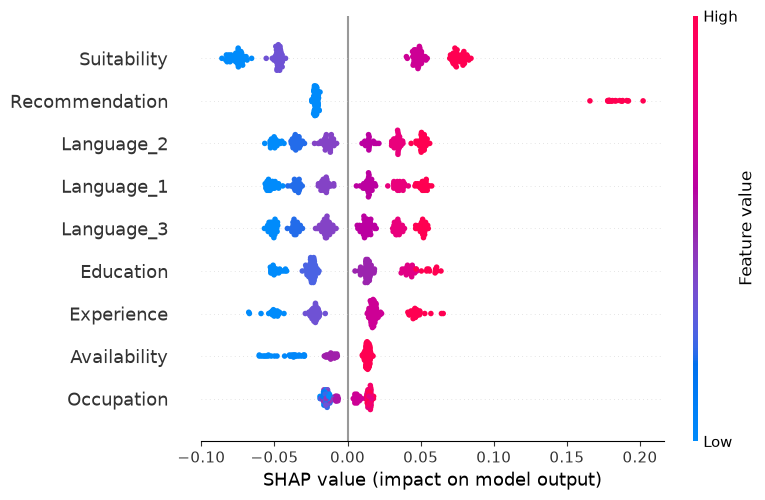

In [38]:
shap.summary_plot(
    shap_values,
    X_shap,
    show=True
)

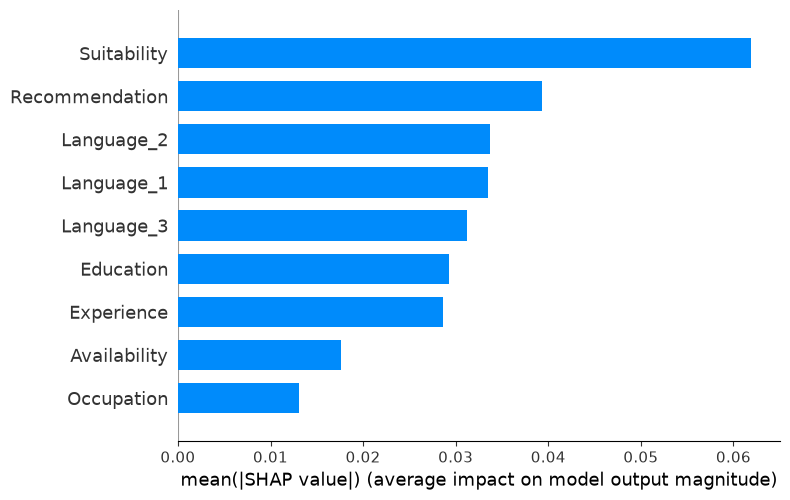

In [39]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar"
)

In [40]:
seeds = [42, 7, 21, 30, 100]

shap_importance_results = {}

for seed in seeds:

    model = RandomForestRegressor(
        n_estimators=100,
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_train, y_train["Blind"])

    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(X_shap)

    importance = np.abs(values).mean(axis=0)

    shap_importance_results[f"Seed_{seed}"] = importance

print("SHAP stability analysis completed!")

SHAP stability analysis completed!


In [41]:
stability_df = pd.DataFrame(
    shap_importance_results,
    index=X_shap.columns
)

stability_df

,Seed_42,Seed_7,Seed_21,Seed_30,Seed_100
Occupation,0.013128,0.012873,0.013062,0.013148,0.013090
Suitability,0.061930,0.061887,0.062031,0.061942,0.061891
Education,0.029242,0.029267,0.029208,0.029229,0.029253
Experience,0.028669,0.028518,0.028588,0.028535,0.028516
Recommendation,0.039327,0.039271,0.039281,0.039334,0.039297
Availability,0.017585,0.017610,0.017581,0.017588,0.017698
Language_1,0.033529,0.033582,0.033503,0.033458,0.033458
Language_2,0.033726,0.033692,0.033721,0.033702,0.033731
Language_3,0.031213,0.031066,0.031198,0.031124,0.031171


In [42]:
rankings = stability_df.rank(
    ascending=False,
    axis=0
)

correlation = rankings.corr(
    method="spearman"
)

correlation

,Seed_42,Seed_7,Seed_21,Seed_30,Seed_100
Seed_42,1.0,1.0,1.0,1.0,1.0
Seed_7,1.0,1.0,1.0,1.0,1.0
Seed_21,1.0,1.0,1.0,1.0,1.0
Seed_30,1.0,1.0,1.0,1.0,1.0
Seed_100,1.0,1.0,1.0,1.0,1.0


In [43]:
importance_summary = pd.DataFrame({
    "Mean_Importance": stability_df.mean(axis=1),
    "Std_Deviation": stability_df.std(axis=1)
})

importance_summary = importance_summary.sort_values(
    by="Mean_Importance",
    ascending=False
)

importance_summary

,Mean_Importance,Std_Deviation
Suitability,0.061936,0.000058
Recommendation,0.039302,0.000028
Language_2,0.033714,0.000017
Language_1,0.033506,0.000052
Language_3,0.031154,0.000060
Education,0.029240,0.000022
Experience,0.028565,0.000065
Availability,0.017612,0.000049
Occupation,0.013060,0.000110


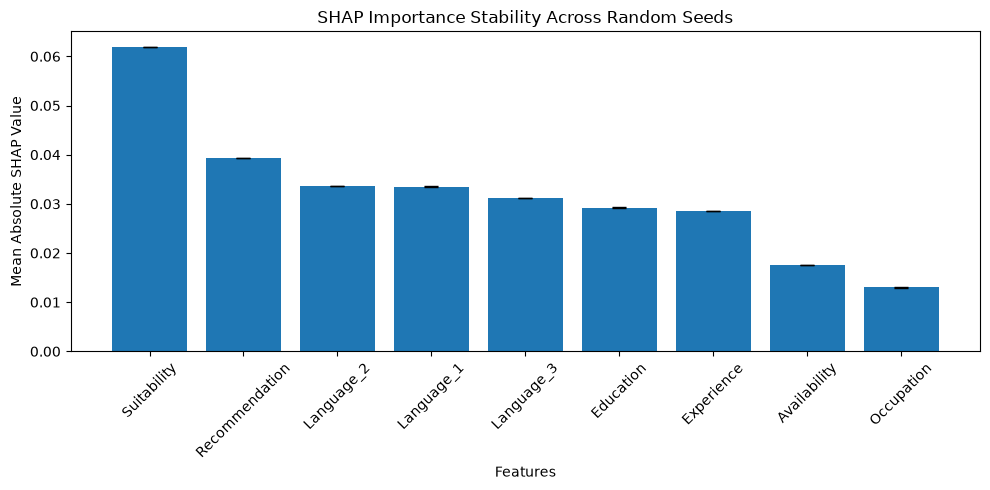

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    importance_summary.index,
    importance_summary["Mean_Importance"],
    yerr=importance_summary["Std_Deviation"],
    capsize=5
)

plt.title("SHAP Importance Stability Across Random Seeds")
plt.xlabel("Features")
plt.ylabel("Mean Absolute SHAP Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
counterfactual_features = [
    "Ethnicity",
    "Gender",
    "Occupation",
    "Suitability",
    "Education",
    "Experience",
    "Recommendation",
    "Availability",
    "Language_1",
    "Language_2",
    "Language_3"
]

X_cf_train = pd.DataFrame(
    faircv["Profiles Train"][:, 0:11],
    columns=counterfactual_features
)

X_cf_test = pd.DataFrame(
    faircv["Profiles Test"][:, 0:11],
    columns=counterfactual_features
)

print("Training shape:", X_cf_train.shape)
print("Testing shape:", X_cf_test.shape)

X_cf_train.head()

Training shape: (19200, 11)
Testing shape: (4800, 11)


,Ethnicity,Gender,Occupation,Suitability,Education,Experience,Recommendation,Availability,Language_1,Language_2,Language_3
0,1.0,0.0,4.0,0.25,0.6,0.8,0.0,1.0,0.6,1.0,0.4
1,2.0,0.0,6.0,1.00,0.4,0.4,0.0,0.8,0.8,0.6,0.4
2,1.0,0.0,5.0,0.25,0.2,0.8,0.0,0.8,0.0,1.0,0.2
3,2.0,1.0,0.0,0.75,0.2,0.4,0.0,0.8,0.0,0.0,1.0
4,1.0,1.0,8.0,0.50,0.2,0.4,1.0,1.0,0.0,1.0,0.4


In [46]:
cf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

cf_model.fit(X_cf_train, y_train["Blind"])

print("Counterfactual analysis model trained successfully!")

Counterfactual analysis model trained successfully!


In [47]:
X_gender_original = X_cf_test.sample(
    n=200,
    random_state=42
).copy()

X_gender_changed = X_gender_original.copy()

print("Original gender distribution:")
print(X_gender_original["Gender"].value_counts())

Original gender distribution:
Gender
0.0    101
1.0     99
Name: count, dtype: int64


In [48]:
X_gender_changed["Gender"] = 1 - X_gender_changed["Gender"]

print("Changed gender distribution:")
print(X_gender_changed["Gender"].value_counts())

Changed gender distribution:
Gender
1.0    101
0.0     99
Name: count, dtype: int64


In [49]:
original_predictions = cf_model.predict(X_gender_original)

changed_predictions = cf_model.predict(X_gender_changed)

gender_score_changes = changed_predictions - original_predictions

print("First 10 Original Predictions:")
print(original_predictions[:10])

print("\nFirst 10 Changed Predictions:")
print(changed_predictions[:10])

print("\nFirst 10 Score Changes:")
print(gender_score_changes[:10])

First 10 Original Predictions:
[0.51687603 0.54424279 0.48819668 0.42317921 0.39204665 0.55407217
 0.5758434  0.31543294 0.53960215 0.42448274]

First 10 Changed Predictions:
[0.51793132 0.5465942  0.48226972 0.41747313 0.39159285 0.55312094
 0.57455546 0.32037636 0.53524174 0.42435754]

First 10 Score Changes:
[ 0.00105529  0.00235141 -0.00592696 -0.00570608 -0.0004538  -0.00095123
 -0.00128794  0.00494341 -0.00436041 -0.0001252 ]


In [50]:
gender_mean_change = np.mean(np.abs(gender_score_changes))
gender_max_change = np.max(np.abs(gender_score_changes))
gender_changed_count = np.sum(np.abs(gender_score_changes) > 0.000001)

print("Gender Counterfactual Analysis")
print("--------------------------------")
print("Mean Absolute Score Change:", gender_mean_change)
print("Maximum Score Change:", gender_max_change)
print("Records with Changed Predictions:", gender_changed_count, "out of 200")

Gender Counterfactual Analysis
--------------------------------
Mean Absolute Score Change: 0.0032873367337060743
Maximum Score Change: 0.015883861116407938
Records with Changed Predictions: 200 out of 200


In [51]:
X_ethnicity_original = X_cf_test.sample(
    n=200,
    random_state=42
).copy()

print("Original ethnicity distribution:")
print(X_ethnicity_original["Ethnicity"].value_counts())

Original ethnicity distribution:
Ethnicity
1.0    77
2.0    64
0.0    59
Name: count, dtype: int64


In [52]:
X_ethnicity_changed_1 = X_ethnicity_original.copy()
X_ethnicity_changed_2 = X_ethnicity_original.copy()

X_ethnicity_changed_1["Ethnicity"] = (
    (X_ethnicity_original["Ethnicity"] + 1) % 3
)

X_ethnicity_changed_2["Ethnicity"] = (
    (X_ethnicity_original["Ethnicity"] + 2) % 3
)

print("Original, first alternative and second alternative:")
print(pd.DataFrame({
    "Original": X_ethnicity_original["Ethnicity"].values[:10],
    "Alternative_1": X_ethnicity_changed_1["Ethnicity"].values[:10],
    "Alternative_2": X_ethnicity_changed_2["Ethnicity"].values[:10]
}))

Original, first alternative and second alternative:
   Original  Alternative_1  Alternative_2
0       1.0            2.0            0.0
1       0.0            1.0            2.0
2       0.0            1.0            2.0
3       2.0            0.0            1.0
4       1.0            2.0            0.0
5       0.0            1.0            2.0
6       1.0            2.0            0.0
7       1.0            2.0            0.0
8       2.0            0.0            1.0
9       2.0            0.0            1.0


In [56]:
# Original predictions
ethnicity_original_predictions = cf_model.predict(
    X_ethnicity_original
)

# Predictions for alternative ethnicity values
ethnicity_changed_predictions_1 = cf_model.predict(
    X_ethnicity_changed_1
)

ethnicity_changed_predictions_2 = cf_model.predict(
    X_ethnicity_changed_2
)

# Calculate score changes
ethnicity_changes_1 = (
    ethnicity_changed_predictions_1 -
    ethnicity_original_predictions
)

ethnicity_changes_2 = (
    ethnicity_changed_predictions_2 -
    ethnicity_original_predictions
)

print("Ethnicity predictions calculated successfully!")
print("First 10 changes:")
print(ethnicity_changes_1[:10])

Ethnicity predictions calculated successfully!
First 10 changes:
[-0.0024276   0.00074214 -0.00089351 -0.00273993 -0.00246193 -0.00117677
 -0.00609088  0.00328664 -0.00836108  0.00353282]


In [57]:
all_ethnicity_changes = np.concatenate([
    ethnicity_changes_1,
    ethnicity_changes_2
])

ethnicity_mean_change = np.mean(
    np.abs(all_ethnicity_changes)
)

ethnicity_max_change = np.max(
    np.abs(all_ethnicity_changes)
)

ethnicity_changed_count = np.sum(
    np.abs(all_ethnicity_changes) > 0.000001
)

print("Ethnicity Counterfactual Analysis")
print("-----------------------------------")
print("Mean Absolute Score Change:", ethnicity_mean_change)
print("Maximum Score Change:", ethnicity_max_change)
print("Changed Predictions:", ethnicity_changed_count, "out of 400")

Ethnicity Counterfactual Analysis
-----------------------------------
Mean Absolute Score Change: 0.0028868459514082346
Maximum Score Change: 0.014995551461833068
Changed Predictions: 399 out of 400


In [58]:
counterfactual_results = pd.DataFrame({
    "Demographic Feature": ["Gender", "Ethnicity"],
    "Mean Absolute Change": [
        gender_mean_change,
        ethnicity_mean_change
    ],
    "Maximum Change": [
        gender_max_change,
        ethnicity_max_change
    ],
    "Changed Predictions": [
        gender_changed_count,
        ethnicity_changed_count
    ],
    "Total Comparisons": [200, 400],
    "Percentage Affected": [
        (gender_changed_count / 200) * 100,
        (ethnicity_changed_count / 400) * 100
    ]
})

counterfactual_results

,Demographic Feature,Mean Absolute Change,Maximum Change,Changed Predictions,Total Comparisons,Percentage Affected
0,Gender,0.003287,0.015884,200,200,100.00
1,Ethnicity,0.002887,0.014996,399,400,99.75


In [59]:
counterfactual_results.to_csv(
    "../results/counterfactual_comparison.csv",
    index=False
)

print("Counterfactual comparison saved successfully!")

Counterfactual comparison saved successfully!


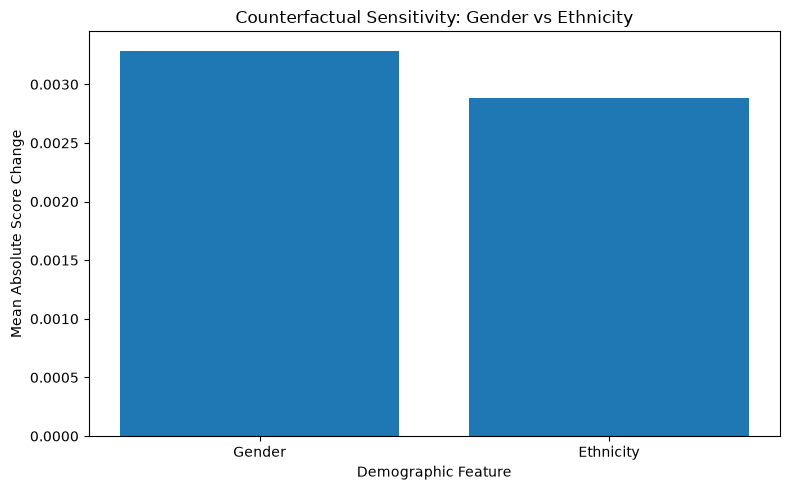

In [60]:
plt.figure(figsize=(8, 5))

plt.bar(
    counterfactual_results["Demographic Feature"],
    counterfactual_results["Mean Absolute Change"]
)

plt.title("Counterfactual Sensitivity: Gender vs Ethnicity")
plt.xlabel("Demographic Feature")
plt.ylabel("Mean Absolute Score Change")

plt.tight_layout()
plt.show()

In [61]:
# Generate predictions on the test dataset
cf_test_predictions = cf_model.predict(X_cf_test)

# Create evaluation dataset
evaluation_df = X_cf_test.copy()

evaluation_df["Actual"] = y_test["Blind"]
evaluation_df["Predicted"] = cf_test_predictions

evaluation_df["Absolute_Error"] = np.abs(
    evaluation_df["Actual"] - evaluation_df["Predicted"]
)

evaluation_df["Squared_Error"] = (
    evaluation_df["Actual"] - evaluation_df["Predicted"]
) ** 2

print("Evaluation dataset prepared!")
evaluation_df.head()

Evaluation dataset prepared!


,Ethnicity,Gender,Occupation,Suitability,Education,Experience,Recommendation,Availability,Language_1,Language_2,Language_3,Actual,Predicted,Absolute_Error,Squared_Error
0,1.0,0.0,0.0,0.75,0.4,1.0,0.0,0.6,0.6,0.6,0.2,0.427979,0.425049,0.002930,8.586694e-06
1,0.0,0.0,3.0,0.25,0.4,0.6,0.0,1.0,0.6,0.2,0.6,0.295753,0.295467,0.000286,8.160250e-08
2,0.0,0.0,4.0,0.25,0.8,0.6,0.0,1.0,0.6,0.6,0.2,0.382433,0.389206,0.006773,4.587544e-05
3,0.0,0.0,9.0,0.50,0.6,0.6,0.0,1.0,0.2,0.2,0.0,0.266385,0.296620,0.030235,9.141282e-04
4,2.0,0.0,5.0,0.25,0.6,0.2,0.0,1.0,0.4,0.8,1.0,0.368853,0.361324,0.007528,5.667542e-05


In [62]:
gender_fairness = evaluation_df.groupby("Gender").agg(
    Records=("Actual", "count"),
    Mean_Actual=("Actual", "mean"),
    Mean_Predicted=("Predicted", "mean"),
    MAE=("Absolute_Error", "mean"),
    RMSE=("Squared_Error", lambda x: np.sqrt(x.mean()))
)

gender_fairness

,Records,Mean_Actual,Mean_Predicted,MAE,RMSE
Gender,,,,,
0.0,2437,0.415260,0.415443,0.017491,0.022736
1.0,2363,0.415336,0.415390,0.017984,0.023822


In [63]:
ethnicity_fairness = evaluation_df.groupby("Ethnicity").agg(
    Records=("Actual", "count"),
    Mean_Actual=("Actual", "mean"),
    Mean_Predicted=("Predicted", "mean"),
    MAE=("Absolute_Error", "mean"),
    RMSE=("Squared_Error", lambda x: np.sqrt(x.mean()))
)

ethnicity_fairness

,Records,Mean_Actual,Mean_Predicted,MAE,RMSE
Ethnicity,,,,,
0.0,1595,0.418057,0.419268,0.018312,0.024375
1.0,1588,0.414272,0.414253,0.017615,0.023004
2.0,1617,0.413583,0.412761,0.017280,0.022420


In [64]:
gender_fairness.to_csv(
    "../results/gender_fairness_analysis.csv"
)

ethnicity_fairness.to_csv(
    "../results/ethnicity_fairness_analysis.csv"
)

print("Group-wise fairness results saved successfully!")

Group-wise fairness results saved successfully!


In [65]:
gender_mae_gap = (
    gender_fairness["MAE"].max() -
    gender_fairness["MAE"].min()
)

gender_rmse_gap = (
    gender_fairness["RMSE"].max() -
    gender_fairness["RMSE"].min()
)

ethnicity_mae_gap = (
    ethnicity_fairness["MAE"].max() -
    ethnicity_fairness["MAE"].min()
)

ethnicity_rmse_gap = (
    ethnicity_fairness["RMSE"].max() -
    ethnicity_fairness["RMSE"].min()
)

print("DEMOGRAPHIC PERFORMANCE GAPS")
print("-----------------------------")
print("Gender MAE Gap:", gender_mae_gap)
print("Gender RMSE Gap:", gender_rmse_gap)
print("Ethnicity MAE Gap:", ethnicity_mae_gap)
print("Ethnicity RMSE Gap:", ethnicity_rmse_gap)

DEMOGRAPHIC PERFORMANCE GAPS
-----------------------------
Gender MAE Gap: 0.0004931291716324532
Gender RMSE Gap: 0.001085496162279917
Ethnicity MAE Gap: 0.0010319069182754964
Ethnicity RMSE Gap: 0.001955147289469557


In [66]:
gap_results = pd.DataFrame({
    "Demographic": ["Gender", "Ethnicity"],
    "MAE_Gap": [gender_mae_gap, ethnicity_mae_gap],
    "RMSE_Gap": [gender_rmse_gap, ethnicity_rmse_gap]
})

gap_results.to_csv(
    "../results/demographic_performance_gaps.csv",
    index=False
)

gap_results

,Demographic,MAE_Gap,RMSE_Gap
0,Gender,0.000493,0.001085
1,Ethnicity,0.001032,0.001955


In [67]:
final_findings = pd.DataFrame({
    "Experiment": [
        "Best Linear Regression Target",
        "Best Random Forest Target",
        "Top SHAP Feature",
        "SHAP Rank Stability",
        "Gender Counterfactual",
        "Ethnicity Counterfactual",
        "Gender MAE Gap",
        "Ethnicity MAE Gap"
    ],
    "Result": [
        "Blind (R2 = 0.9912)",
        "Blind (R2 = 0.9686)",
        "Suitability",
        "Spearman correlation = 1.0",
        "200 out of 200 changed",
        "399 out of 400 changed",
        str(round(gender_mae_gap, 6)),
        str(round(ethnicity_mae_gap, 6))
    ]
})

final_findings

,Experiment,Result
0,Best Linear Regression Target,Blind (R2 = 0.9912)
1,Best Random Forest Target,Blind (R2 = 0.9686)
2,Top SHAP Feature,Suitability
3,SHAP Rank Stability,Spearman correlation = 1.0
4,Gender Counterfactual,200 out of 200 changed
5,Ethnicity Counterfactual,399 out of 400 changed
6,Gender MAE Gap,0.000493
7,Ethnicity MAE Gap,0.001032


In [68]:
final_findings.to_csv(
    "../results/final_project_findings.csv",
    index=False
)

print("Final project findings saved successfully!")

Final project findings saved successfully!


In [69]:
# Get the scaler and trained Linear Regression model
scaler = lr_model.named_steps["standardscaler"]

linear_estimator = lr_model.named_steps["linearregression"]

# Transform the same SHAP sample
X_shap_scaled = scaler.transform(X_shap)

# Select background data
X_background = X_train.sample(
    n=100,
    random_state=42
)

X_background_scaled = scaler.transform(X_background)

print("Data prepared for Linear Regression SHAP!")
print("SHAP sample shape:", X_shap_scaled.shape)
print("Background shape:", X_background_scaled.shape)

Data prepared for Linear Regression SHAP!
SHAP sample shape: (200, 9)
Background shape: (100, 9)


In [70]:
lr_explainer = shap.LinearExplainer(
    linear_estimator,
    X_background_scaled
)

lr_shap_values = lr_explainer.shap_values(
    X_shap_scaled
)

print("Linear Regression SHAP calculated successfully!")
print("SHAP values shape:", np.array(lr_shap_values).shape)

Linear Regression SHAP calculated successfully!
SHAP values shape: (200, 9)


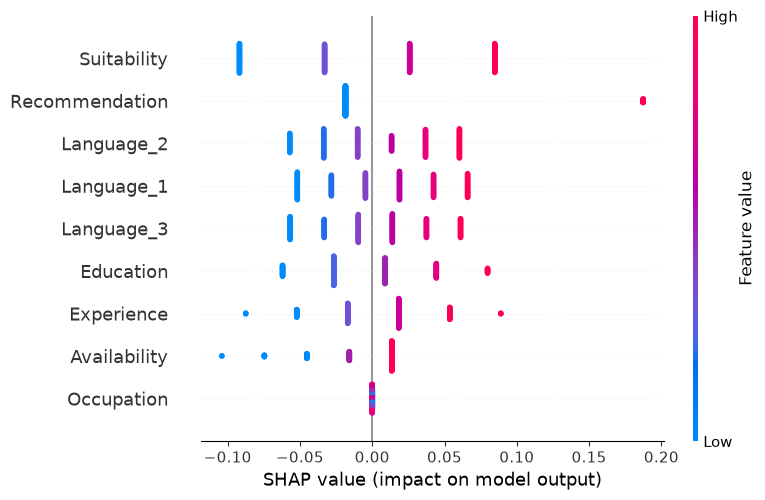

In [71]:
shap.summary_plot(
    lr_shap_values,
    X_shap,
    show=True
)

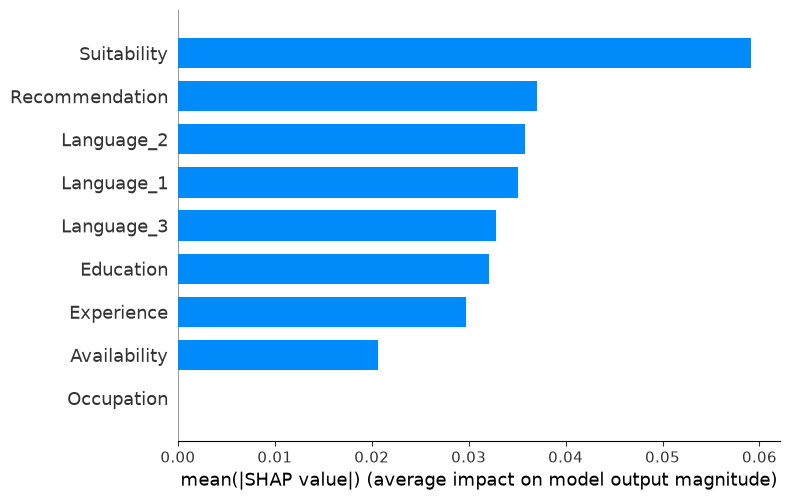

In [72]:
shap.summary_plot(
    lr_shap_values,
    X_shap,
    plot_type="bar",
    show=True
)

In [73]:
from scipy.stats import spearmanr

# Calculate mean absolute SHAP importance
rf_importance = np.abs(shap_values).mean(axis=0)
lr_importance = np.abs(lr_shap_values).mean(axis=0)

# Create comparison table
shap_comparison = pd.DataFrame({
    "Feature": X_shap.columns,
    "Random_Forest_Importance": rf_importance,
    "Linear_Regression_Importance": lr_importance
})

# Calculate feature rankings
shap_comparison["RF_Rank"] = (
    shap_comparison["Random_Forest_Importance"]
    .rank(ascending=False, method="min")
)

shap_comparison["LR_Rank"] = (
    shap_comparison["Linear_Regression_Importance"]
    .rank(ascending=False, method="min")
)

# Calculate ranking agreement
correlation, p_value = spearmanr(
    shap_comparison["RF_Rank"],
    shap_comparison["LR_Rank"]
)

print("SHAP Importance Comparison:")
display(shap_comparison.sort_values("RF_Rank"))

print("\nSpearman Rank Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 6))

# Save results
shap_comparison.to_csv(
    "../results/shap_model_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")

SHAP Importance Comparison:


,Feature,Random_Forest_Importance,Linear_Regression_Importance,RF_Rank,LR_Rank
1,Suitability,0.061930,0.059162,1.0,1.0
4,Recommendation,0.039327,0.037099,2.0,2.0
7,Language_2,0.033726,0.035856,3.0,3.0
6,Language_1,0.033529,0.035052,4.0,4.0
8,Language_3,0.031213,0.032850,5.0,5.0
2,Education,0.029242,0.032083,6.0,6.0
3,Experience,0.028669,0.029773,7.0,7.0
5,Availability,0.017585,0.020652,8.0,8.0
0,Occupation,0.013128,0.000040,9.0,9.0



Spearman Rank Correlation: 1.0
P-value: 0.0

Comparison saved successfully!


In [74]:
shap_findings = pd.DataFrame({
    "Metric": [
        "Top feature - Random Forest",
        "Top feature - Linear Regression",
        "Spearman rank correlation",
        "Number of features compared",
        "Number of matching feature ranks",
        "SHAP sample size"
    ],
    "Result": [
        "Suitability",
        "Suitability",
        round(correlation, 4),
        len(shap_comparison),
        (shap_comparison["RF_Rank"] == shap_comparison["LR_Rank"]).sum(),
        len(X_shap)
    ]
})

display(shap_findings)

shap_findings.to_csv(
    "../results/strengthened_shap_findings.csv",
    index=False
)

print("Strengthened SHAP findings saved successfully!")

,Metric,Result
0,Top feature - Random Forest,Suitability
1,Top feature - Linear Regression,Suitability
2,Spearman rank correlation,1.0
3,Number of features compared,9
4,Number of matching feature ranks,9
5,SHAP sample size,200


Strengthened SHAP findings saved successfully!


In [75]:
print("ETHNICITY VALUES:")
print("Train:", np.unique(faircv["Profiles Train"][:, 0]))
print("Test:", np.unique(faircv["Profiles Test"][:, 0]))

print("\nGENDER VALUES:")
print("Train:", np.unique(faircv["Profiles Train"][:, 1]))
print("Test:", np.unique(faircv["Profiles Test"][:, 1]))

print("\nFEATURE VALUES:")
for i in range(2, 11):
    print(f"Column {i}:",
          np.unique(faircv["Profiles Train"][:, i]))

ETHNICITY VALUES:
Train: [0. 1. 2.]
Test: [0. 1. 2.]

GENDER VALUES:
Train: [0. 1.]
Test: [0. 1.]

FEATURE VALUES:
Column 2: [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]
Column 3: [0.25 0.5  0.75 1.  ]
Column 4: [0.2 0.4 0.6 0.8 1. ]
Column 5: [0.  0.2 0.4 0.6 0.8 1. ]
Column 6: [0. 1.]
Column 7: [0.2 0.4 0.6 0.8 1. ]
Column 8: [0.  0.2 0.4 0.6 0.8 1. ]
Column 9: [0.  0.2 0.4 0.6 0.8 1. ]
Column 10: [0.  0.2 0.4 0.6 0.8 1. ]


In [76]:
import os

results_folder = "../results"

print("SAVED PROJECT RESULT FILES")
print("-" * 40)

for file in sorted(os.listdir(results_folder)):
    print(file)

SAVED PROJECT RESULT FILES
----------------------------------------
all_model_comparison.csv
counterfactual_comparison.csv
demographic_performance_gaps.csv
ethnicity_fairness_analysis.csv
final_project_findings.csv
gender_fairness_analysis.csv
linear_regression_results.csv
shap_model_comparison.csv
strengthened_shap_findings.csv


In [77]:
import pandas as pd
import os

results_folder = "../results"

files_to_check = [
    "all_model_comparison.csv",
    "counterfactual_comparison.csv",
    "demographic_performance_gaps.csv",
    "gender_fairness_analysis.csv",
    "ethnicity_fairness_analysis.csv",
    "final_project_findings.csv",
    "shap_model_comparison.csv",
    "strengthened_shap_findings.csv"
]

for file in files_to_check:
    print("\n" + "=" * 60)
    print(file.upper())
    print("=" * 60)

    df = pd.read_csv(os.path.join(results_folder, file))
    display(df)


ALL_MODEL_COMPARISON.CSV


,Model,Target,MAE,MSE,RMSE,R2 Score
0,Linear Regression,Blind,0.009399,0.000139,0.011774,0.991156
1,Linear Regression,Gender,0.047352,0.002531,0.050305,0.859985
2,Linear Regression,Ethnicity,0.061705,0.005256,0.072498,0.760396
3,Random Forest,Blind,0.016885,0.000492,0.022182,0.968606
4,Random Forest,Gender,0.049699,0.003339,0.057787,0.815240
5,Random Forest,Ethnicity,0.066468,0.006691,0.081799,0.694977



COUNTERFACTUAL_COMPARISON.CSV


,Demographic Feature,Mean Absolute Change,Maximum Change,Changed Predictions,Total Comparisons,Percentage Affected
0,Gender,0.003287,0.015884,200,200,100.00
1,Ethnicity,0.002887,0.014996,399,400,99.75



DEMOGRAPHIC_PERFORMANCE_GAPS.CSV


,Demographic,MAE_Gap,RMSE_Gap
0,Gender,0.000493,0.001085
1,Ethnicity,0.001032,0.001955


... (6 outputs left out)


SHAP_MODEL_COMPARISON.CSV


,Feature,Random_Forest_Importance,Linear_Regression_Importance,RF_Rank,LR_Rank
0,Occupation,0.013128,0.000040,9.0,9.0
1,Suitability,0.061930,0.059162,1.0,1.0
2,Education,0.029242,0.032083,6.0,6.0
3,Experience,0.028669,0.029773,7.0,7.0
4,Recommendation,0.039327,0.037099,2.0,2.0
5,Availability,0.017585,0.020652,8.0,8.0
6,Language_1,0.033529,0.035052,4.0,4.0
7,Language_2,0.033726,0.035856,3.0,3.0
8,Language_3,0.031213,0.032850,5.0,5.0



STRENGTHENED_SHAP_FINDINGS.CSV


,Metric,Result
0,Top feature - Random Forest,Suitability
1,Top feature - Linear Regression,Suitability
2,Spearman rank correlation,1.0
3,Number of features compared,9
4,Number of matching feature ranks,9
5,SHAP sample size,200
